# exp02: Perbandingan Algoritma

Membandingkan Logistic Regression, SVM RBF, Random Forest, Extra Trees, XGBoost, dan CatBoost pada fitur original. Parameter tiap model dipilih dari registry yang sama seperti batch-01 lama, menggunakan tiga inner fold berbasis peserta.

Dataset: good_acceptable, window 25 detik, langkah 5 detik. Target dibaca langsung dari cognitive_load_label (Low=0, Medium=1, High=2), termasuk Low pada fase nonpengerjaan yang sudah diberi label dalam dataset v2. Identitas, konteks CodeArrange, dan kualitas hanya menjadi metadata/pembagi evaluasi, bukan fitur prediksi.

### Konfigurasi

Memakai runtime lokal yang sudah diverifikasi terhadap artefak batch-01 lama. Run ini mengevaluasi seluruh peserta dengan seed 42 dan 300 tree/iterasi untuk model berbasis pohon. Checkpoint yang cocok dilanjutkan; hasil dengan identitas data, kode, atau environment berbeda tidak dicampur.

In [1]:
from pathlib import Path
import json
import sys

location = Path.cwd().resolve()
BATCH = next(p for p in (location, *location.parents) if (p / "shared" / "design_registry.json").is_file())
sys.path.insert(0, str(BATCH))

import pandas as pd
from IPython.display import display, Image
from shared import data, design
from shared.runner import Config, run

EXPERIMENT = "exp02"
WINDOW = "window_25s_step_5s"
DATASET_PATH = data.ROOT / "analysis_sessions" / "dataset_fusion" / "output" / "v2_session_phase" / WINDOW / "good_acceptable.csv"
config = Config(dataset_path=DATASET_PATH, output_root=BATCH / "outputs", experiment=EXPERIMENT)
print(DATASET_PATH)

D:\Penelitian Pak Hadi\Adaptive-IDE\analysis_sessions\dataset_fusion\output\v2_session_phase\window_25s_step_5s\good_acceptable.csv


### Dataset dan Kandidat

Memeriksa label, ID window, timestamp, dan allowlist sensor sebelum training. Tidak ada pemetaan ulang dari difficulty. Missing value dan fitur konstan ditangani pada training masing-masing fold, bukan secara global.

In [2]:
frame = data.load_dataset(DATASET_PATH)
display(pd.DataFrame(data.describe_data(frame)["class_counts"].items(), columns=["label", "windows"]))
specifications = design.registry(EXPERIMENT)
display(pd.DataFrame([{**{k: v for k, v in item.items() if k != "candidates"}, "candidate_count": len(item["candidates"])} for item in specifications]))
print(f"{len(frame)} windows; {frame.participant_id.nunique()} participants; {len(data.FEATURES)} base sensor features")

,label,windows
0,Low,666
1,Medium,968
2,High,1077


,id,model,scaler,tune,variant,candidate_count
0,logistic,logistic,standard,True,original,6
1,svm,svm,standard,True,original,12
2,random_forest,random_forest,NaN,True,original,12
3,extra_trees,extra_trees,NaN,True,original,12
4,xgboost,xgboost,NaN,True,original,12
5,catboost,catboost,NaN,True,original,12


2711 windows; 13 participants; 26 base sensor features


### Fold dan Training

Leave-one-participant-out menghasilkan satu prediksi test untuk setiap window. Tiga inner group fold, bila diperlukan tuning, hanya menggunakan peserta training. Kriteria seleksi adalah macro-F1 gabungan prediksi inner; parameter terpilih lalu dilatih ulang pada seluruh outer training. Imputasi, scaler, feature selection, dan resampling tidak melihat outer test.

Cache menyimpan hasil fit/prediksi dengan hash data, urutan ID split, pipeline, parameter, seed, kode, dan paket. Hash output diperiksa sebelum melanjutkan checkpoint.

In [3]:
folds = data.make_folds(frame)
display(pd.DataFrame([{"fold": f["fold_id"], "test_participant": f["participant_id"], "train_windows": len(f["train"]), "test_windows": len(f["test"]), "inner_folds": len(f["inner"])} for f in folds]))
RESULT_DIR = run(config)
print(RESULT_DIR)

,fold,test_participant,train_windows,test_windows,inner_folds
0,fold_00,Andrean,2419,292,3
1,fold_01,Andreas,2566,145,3
2,fold_02,Athaya,2490,221,3
3,fold_03,Fabian,2437,274,3
4,fold_04,Rafi,2413,298,3
5,fold_05,Savitri,2453,258,3
6,fold_06,Shakilla,2617,94,3
7,fold_07,Tio,2465,246,3
8,fold_08,faqih,2446,265,3
9,fold_09,ikhsan,2499,212,3


exp02 / 25s / 1/78 / fold_00 / svm


exp02 / 25s / 2/78 / fold_00 / logistic


exp02 / 25s / 3/78 / fold_00 / random_forest


exp02 / 25s / 4/78 / fold_00 / catboost


exp02 / 25s / 5/78 / fold_00 / extra_trees


... (72 outputs left out)

exp02 / 25s / 78/78 / fold_12 / catboost


        model  accuracy  balanced_accuracy  macro_f1  windows
     catboost  0.303209           0.311893  0.301836     2711
  extra_trees  0.340096           0.331205  0.331029     2711
     logistic  0.343047           0.341358  0.339496     2711
random_forest  0.335669           0.329040  0.328697     2711
          svm  0.332719           0.330417  0.328405     2711
      xgboost  0.292512           0.299962  0.291466     2711


Completed: D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp02\window_25s_step_5s\full_9d14aec7eb55


D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp02\window_25s_step_5s\full_9d14aec7eb55


### Evaluasi

Macro-F1 pooled pada tiga kelas menjadi metrik utama. Accuracy, balanced accuracy, precision/recall/F1 per kelas, dan variasi antarorang melengkapi penilaian. Kelas tanpa contoh pada test seseorang tetap kosong pada laporan kelas, bukan dianggap performa nol.

In [4]:
metrics = pd.read_csv(RESULT_DIR / "metrics.csv").sort_values("macro_f1", ascending=False)
display(metrics)
classes = pd.read_csv(RESULT_DIR / "class_metrics.csv")
display(classes[classes.scope.eq("pooled")].drop(columns=["participant_id"], errors="ignore"))
display(pd.read_csv(RESULT_DIR / "participant_summary.csv", header=[0, 1], index_col=0))

,model,accuracy,balanced_accuracy,macro_f1,windows
2,logistic,0.343047,0.341358,0.339496,2711
1,extra_trees,0.340096,0.331205,0.331029,2711
3,random_forest,0.335669,0.329040,0.328697,2711
4,svm,0.332719,0.330417,0.328405,2711
0,catboost,0.303209,0.311893,0.301836,2711
5,xgboost,0.292512,0.299962,0.291466,2711


,scope,model,label,precision,recall,f1,support
0,pooled,catboost,Low,0.273465,0.354354,0.308698,666
1,pooled,catboost,Medium,0.328111,0.367769,0.346810,968
2,pooled,catboost,High,0.301442,0.213556,0.250000,1077
42,pooled,extra_trees,Low,0.268437,0.273273,0.270833,666
43,pooled,extra_trees,Medium,0.340471,0.328512,0.334385,968
44,pooled,extra_trees,High,0.383985,0.391829,0.387868,1077
84,pooled,logistic,Low,0.287220,0.327327,0.305965,666
85,pooled,logistic,Medium,0.360084,0.352273,0.356136,968
86,pooled,logistic,High,0.369154,0.344475,0.356388,1077
126,pooled,random_forest,Low,0.268895,0.277778,0.273264,666


accuracy                     balanced_accuracy            \
                    min    median       max               min    median   
model                                                                     
catboost       0.000000  0.308943  0.514286          0.000000  0.324230   
extra_trees    0.000000  0.359589  0.529412          0.000000  0.346727   
logistic       0.026667  0.342857  0.520134          0.036364  0.333333   
random_forest  0.046667  0.344371  0.529412          0.028409  0.370537   
svm            0.053191  0.337748  0.524887          0.087081  0.350652   
xgboost        0.010638  0.317829  0.409524          0.005682  0.334395   

                         macro_f1                      
                    max       min    median       max  
model                                                  
catboost       0.540009  0.000000  0.250917  0.481993  
extra_trees    0.525920  0.000000  0.277527  0.444736  
logistic       0.495297  0.064516  0.230980  0.488798  
random_forest  0.512013  0.053763  0.309543  0.420610  
svm            0.513433  0.102145  0.322580  0.434578  
xgboost        0.398914  0.011236  0.258167  0.392653

### Confusion Matrix

Baris adalah label referensi, kolom adalah prediksi. Diagonal menunjukkan recall kelas pada gambar ternormalisasi. Maksimal enam model ditampilkan di notebook; seluruh confusion matrix tersimpan pada direktori hasil.

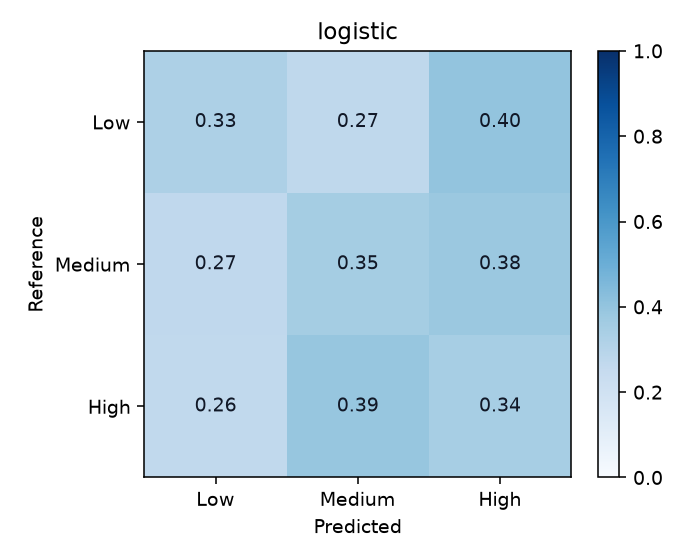

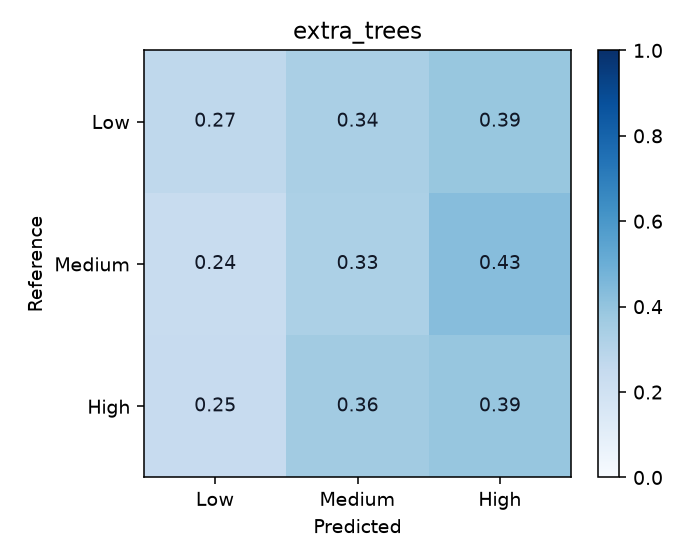

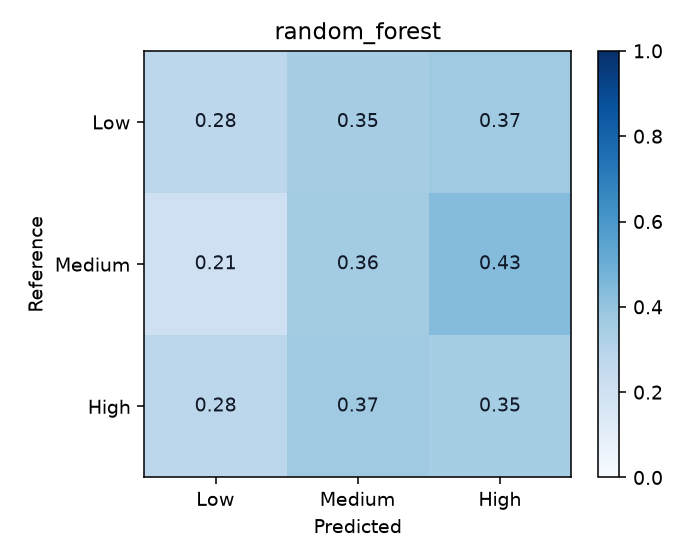

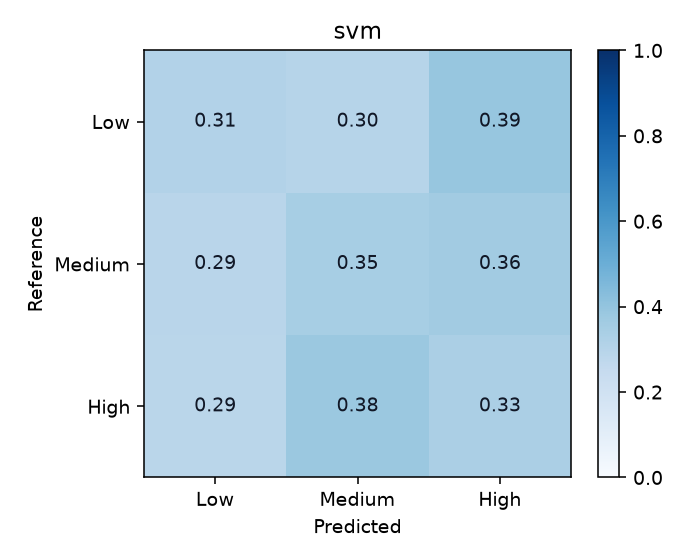

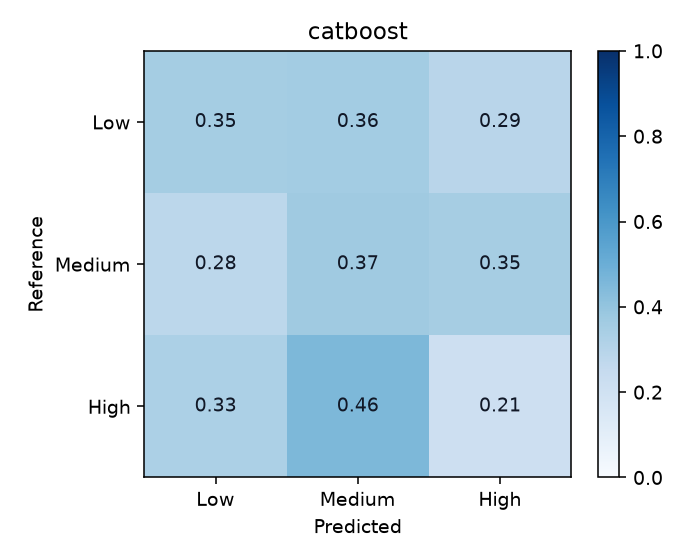

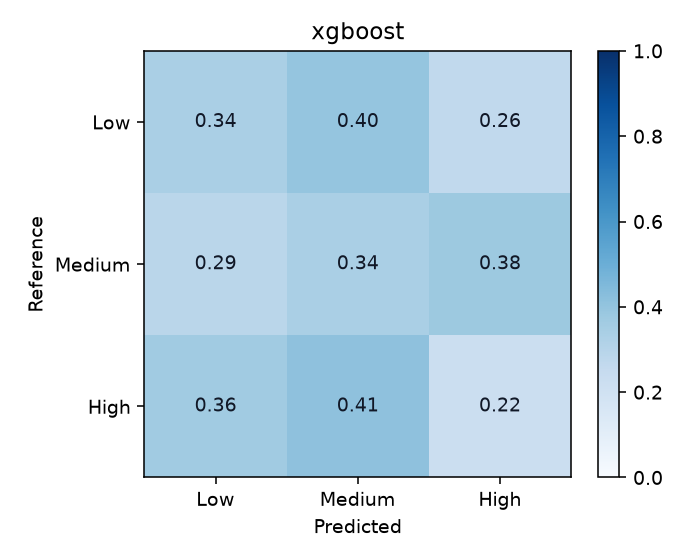

In [5]:
for name in metrics.model.head(6):
    display(Image(filename=str(RESULT_DIR / "figures" / f"{name}_normalized.png")))

### Artefak

Prediksi, manifest, pencarian kandidat, konfigurasi preprocessing, metrik, dan figure tersedia untuk audit. Bobot model dan cache disimpan lokal tetapi tidak masuk Git. Sumber dataset serta arsip old-dataset tidak diubah.

In [6]:
summary = json.loads((RESULT_DIR / "summary.json").read_text())
assert summary["status"] == "complete"
assert summary["evaluated_folds"] == frame.participant_id.nunique()
print(f"Status: {summary['status']}")
print(f"Output: {RESULT_DIR}")

Status: complete
Output: D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp02\window_25s_step_5s\full_9d14aec7eb55
